# Five-method robust benchmark

**Author: Mohammad ALbaraj**

[Notebook index](README.md) · [Main project](../README.md)

Run cells from top to bottom. Saved results and fresh examples are labeled separately. Scientific source modules remain the authoritative implementation.


In [1]:
from pathlib import Path
import sys, json, csv
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, Code

# Works when launched from the repository root or any notebook subdirectory.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / 'CITATION.cff').exists() and (p / 'all work').is_dir())
if str(ROOT / 'notebooks') not in sys.path:
    sys.path.insert(0, str(ROOT / 'notebooks'))
from notebook_support import (METHODS, ORIGINAL, NOMINAL, ROBUST, study, load_json,
    load_csv, show_table, show_source, source_index, load_runs, fitness_summary,
    convergence_plot, validation_rows, validation_summary, figures, file_links,
    show_figures, gallery, isolated_python, demo_source)
plt.rcParams.update({'figure.dpi': 100, 'font.size': 10})
print('Project loaded. Default cells do not launch full optimization campaigns.')


Project loaded. Default cells do not launch full optimization campaigns.


## Experiment contract
There are 150 main searches: five methods × 30 seeds × 3,264 unique evaluations. Initialization counts, duplicates are cached, and the last batch is truncated at the budget. Nominal uses six training cases; robust uses 30.


In [2]:
MODE='robust'
BENCHMARK=NOMINAL if MODE=='nominal' else ROBUST
contract=load_json(BENCHMARK/'results/contract.json')
show_table([{'field':k,'value':v} for k,v in contract.items() if k not in ['configuration','code_sha256','training_cases','validation_cases']])
show_table([r for r in fitness_summary(ORIGINAL) if r['regime']==MODE])


field,value
budget,3264
seeds,"[11, 29, 47, 101, 102, 103, 104, 105, 106, 107, 108, 109, 110, 111, 112, 113, 114, 115, 116, 117, 118, 119, 120, 121, 122, 123, 124, 125, 126, 127]"
methods,"[""GA"", ""PSO"", ""CSO"", ""DSA"", ""CMA-ES""]"
uncertainty_factors,"[[""Jxx"", 0, 0.15], [""Jyy"", 1, 0.15], [""Jzz"", 2, 0.15], [""motor_tau"", 10, 0.3], [""Ct"", 4, 0.1], [""Cm"", 5, 0.1], [""damping_x"", 6, 0.3], [""damping_y"", 7, 0.3], [""damping_z"", 8, 0.3]]"
training_seed,20261005
validation_seed,20261006


method,regime,runs,best,median,mean,sample_sd,feasible
GA,robust,30,0.06573136108055574,0.06699187362751968,0.0670648903446438,0.0009680660401343237,30
PSO,robust,30,0.06515258231085962,0.06573683780613984,0.06612486125976656,0.0009329427432311508,30
CSO,robust,30,0.07536530816958906,0.08594910805458739,0.0864914037604736,0.006837963816693089,30
DSA,robust,30,0.06650325721236684,0.07020261902729469,0.07004076356282862,0.002327064182525687,30
CMA-ES,robust,30,0.06540049914089047,0.06669607516221868,0.06679798006541089,0.0011446261578759687,30


## Convergence from raw evaluation ledgers
The band is the across-seed interquartile range, not a confidence band on future control performance.


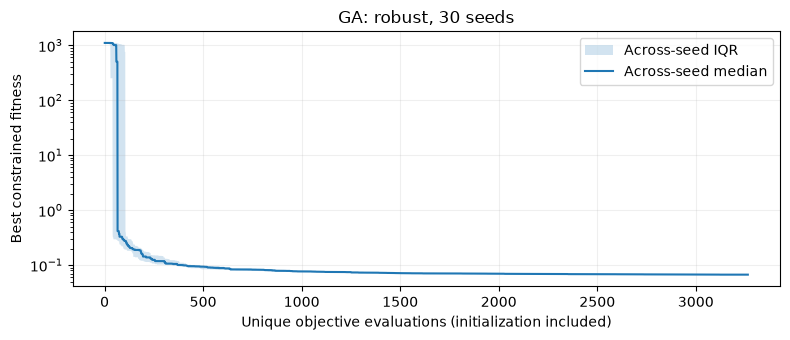

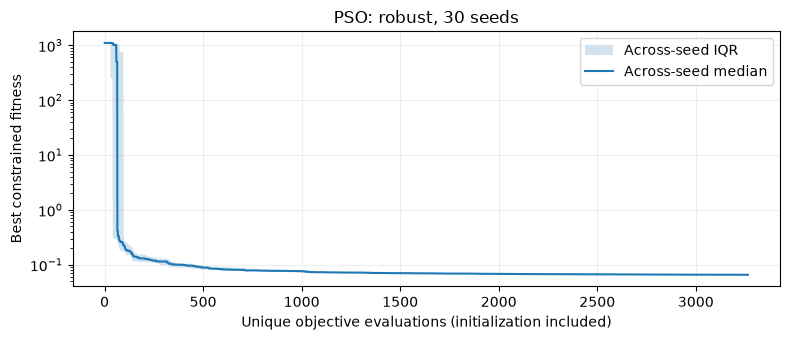

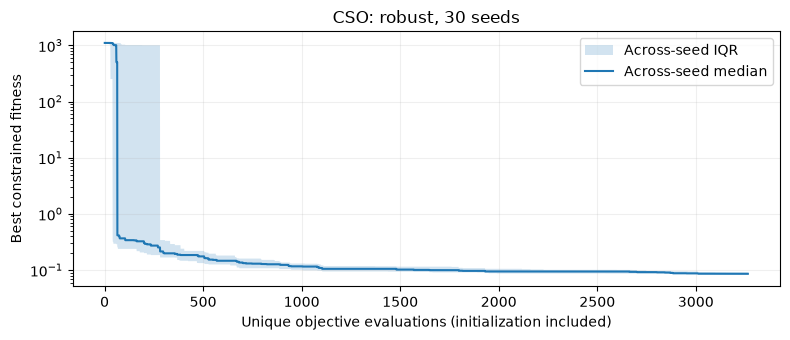

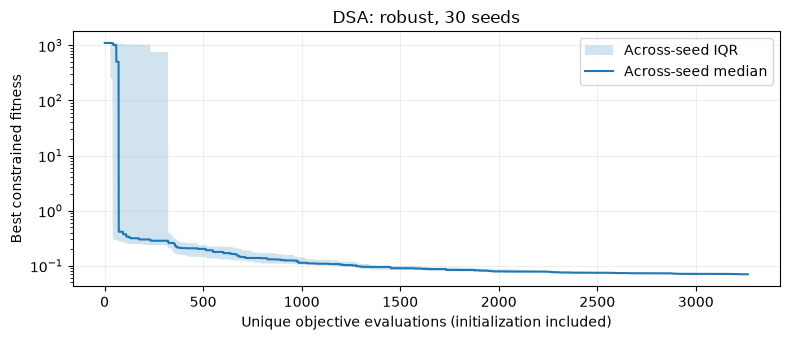

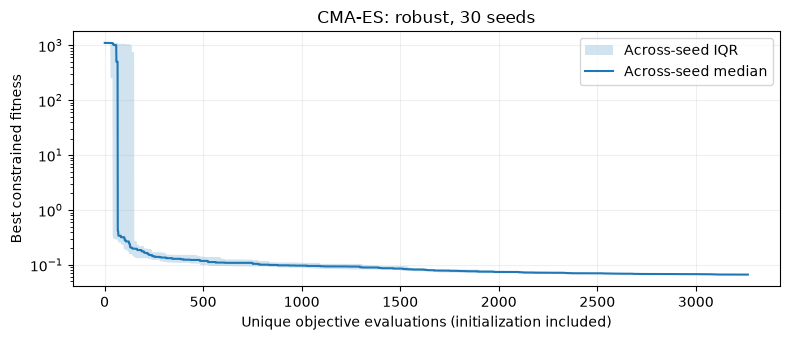

In [3]:
for method in ORIGINAL:
    convergence_plot(method,MODE)


## Selected controllers and statistical metadata
Selections use training fitness. The median representative is an actual run near the median, not a vector of median gains.


In [4]:
show_table(load_csv(BENCHMARK/'results/selected_candidates.csv'),limit=25)
display(Code(json.dumps(load_json(BENCHMARK/'results/statistics.json'),indent=2),language='json'))


method,selection,seed,fitness,mc_passes,boundary_passes,combined_passes,joint_boundary_passes,joint_boundary_cases
GA,best,121,0.06573136108055574,300,53,0,1408,1536
GA,median,124,0.06693617736930814,300,53,0,1408,1536
PSO,best,111,0.06515258231085962,300,53,0,1344,1536
PSO,median,116,0.0658212854197488,300,53,0,1344,1536
CSO,best,114,0.07536530816958906,300,54,0,1536,1536
CSO,median,115,0.08607850274748287,300,54,0,1536,1536
DSA,best,118,0.06650325721236684,300,53,0,1280,1536
DSA,median,105,0.07008450951571661,300,54,0,1472,1536
CMA-ES,best,47,0.06540049914089047,300,53,0,1344,1536
CMA-ES,median,109,0.06669852176190683,300,53,0,1408,1536


{
  "friedman_statistic": 92.82666666666671,
  "permutation_p": 4.999750012499375e-05,
  "permutations": 20000,
  "bootstrap_resamples": 10000,
  "seed": 7102026,
  "notes": "Inference over optimizer seeds on one fixed problem. Wilcoxon assumes symmetric paired differences. CI not multiplicity adjusted."
}

## Budget implementation and figures


class Budget:
    def __init__(self,cfg,limit,pool,objective=None):
        self.cfg=cfg; self.limit=limit; self.pool=pool; self.objective=objective
        self.cache={}; self.best=float('inf'); self.point=None; self.ledger=[]; self.history=[]
        self.iteration=0; self.proposals=0; self.start=time.perf_counter(); self.stalls=0
    def raw(self,p):
        g=decode(p,self.cfg)
        f=self.objective(g) if self.objective else evaluate(g,training_scenarios(),self.cfg)
        if not np.isfinite(f): raise FloatingPointError('Nonfinite objective')
        return float(f)
    def score(self,points):
        points=np.asarray(points); self.proposals+=len(points)
        assert np.isfinite(points).all() and (points>=0).all() and (points<=1).all()
        keys=[tuple(np.round(p,13)) for p in points]; new={}
        for k,p in zip(keys,points):
            if k not in self.cache and k not in new: new[k]=p.copy()
        items=list(new.items())[:self.limit-len(self.cache)]
        vals=list(self.pool.map(self.raw,[p for _,p in items])) if self.pool else [self.raw(p) for _,p in items]
        for (key,p),f in zip(items,vals):
            self.cache[key]=f
            if f<self.best: self.best=f; self.point=p.copy()
            self.ledger.append([len(self.cache),self.iteration,f,self.best,*p.tolist()])
        self.history.append({'iteration':self.iteration,'evaluations':len(self.cache),'best':self.best,'proposals':self.proposals})
        if len(self.cache)==self.limit: raise BudgetExhausted()
        self.stalls=0 if items else self.stalls+1
        if self.stalls>100: raise RuntimeError('No new evaluations for 100 batches; no fake padding allowed')
        return np.array([self.cache[k] for k in keys])
    def progress(self): return max(0,min(1,(len(self.cache)-64)/(self.limit-64)))

**all work/robustness 30 seed study/results/plots/01_training_fitness.png**

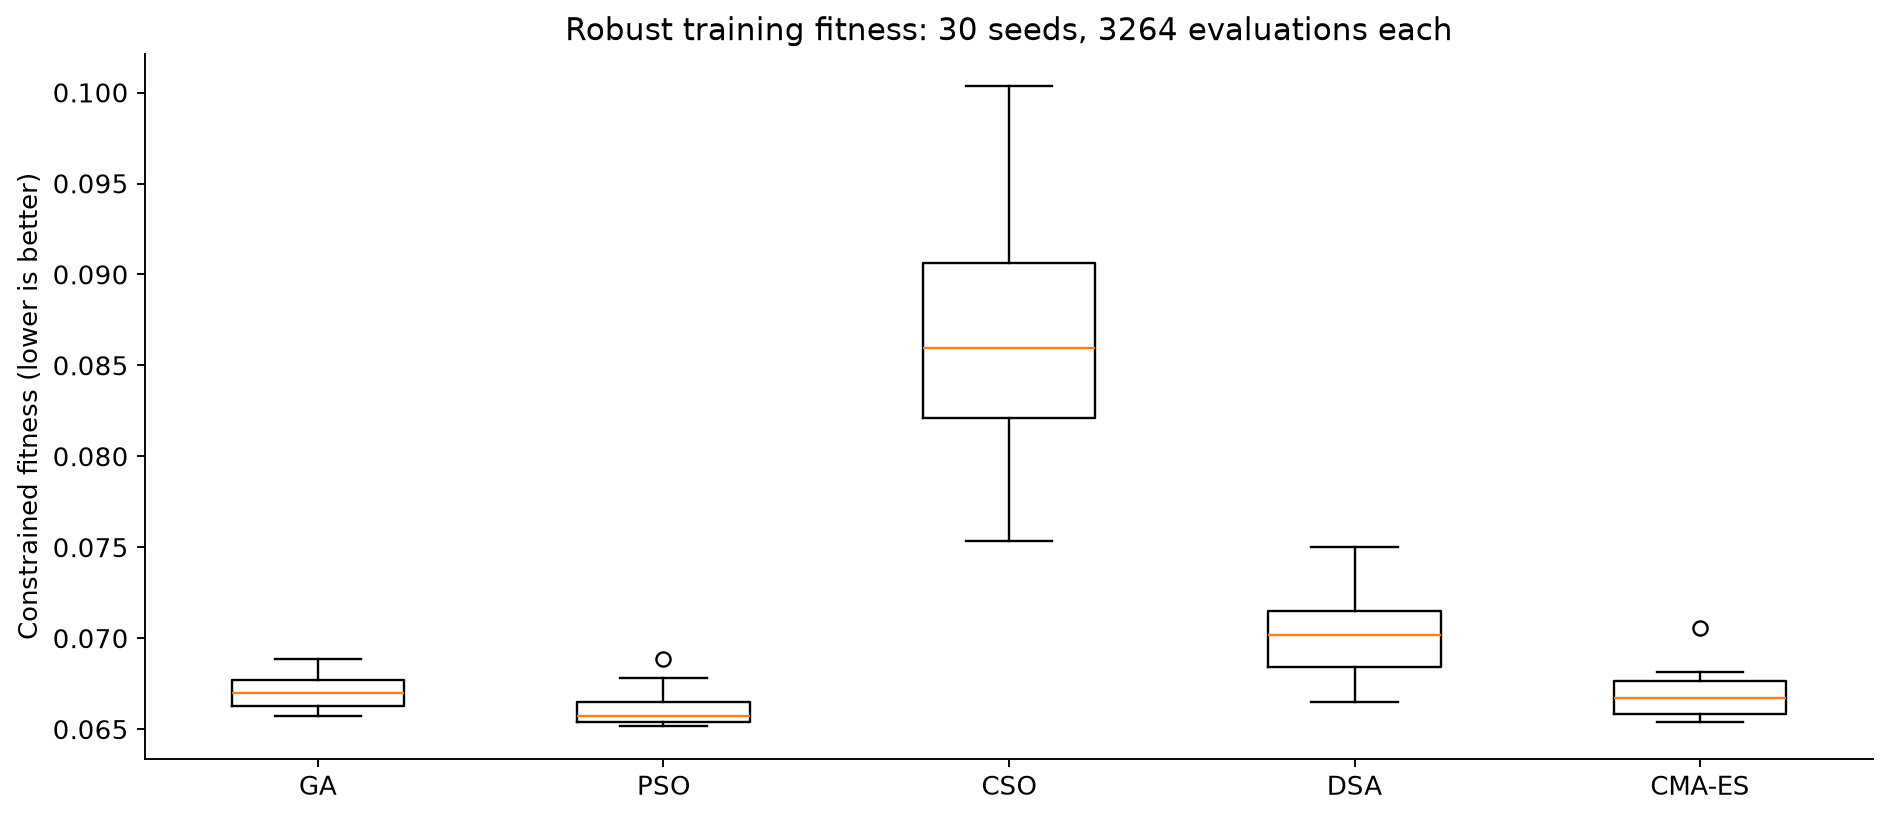

**all work/robustness 30 seed study/results/plots/02_convergence.png**

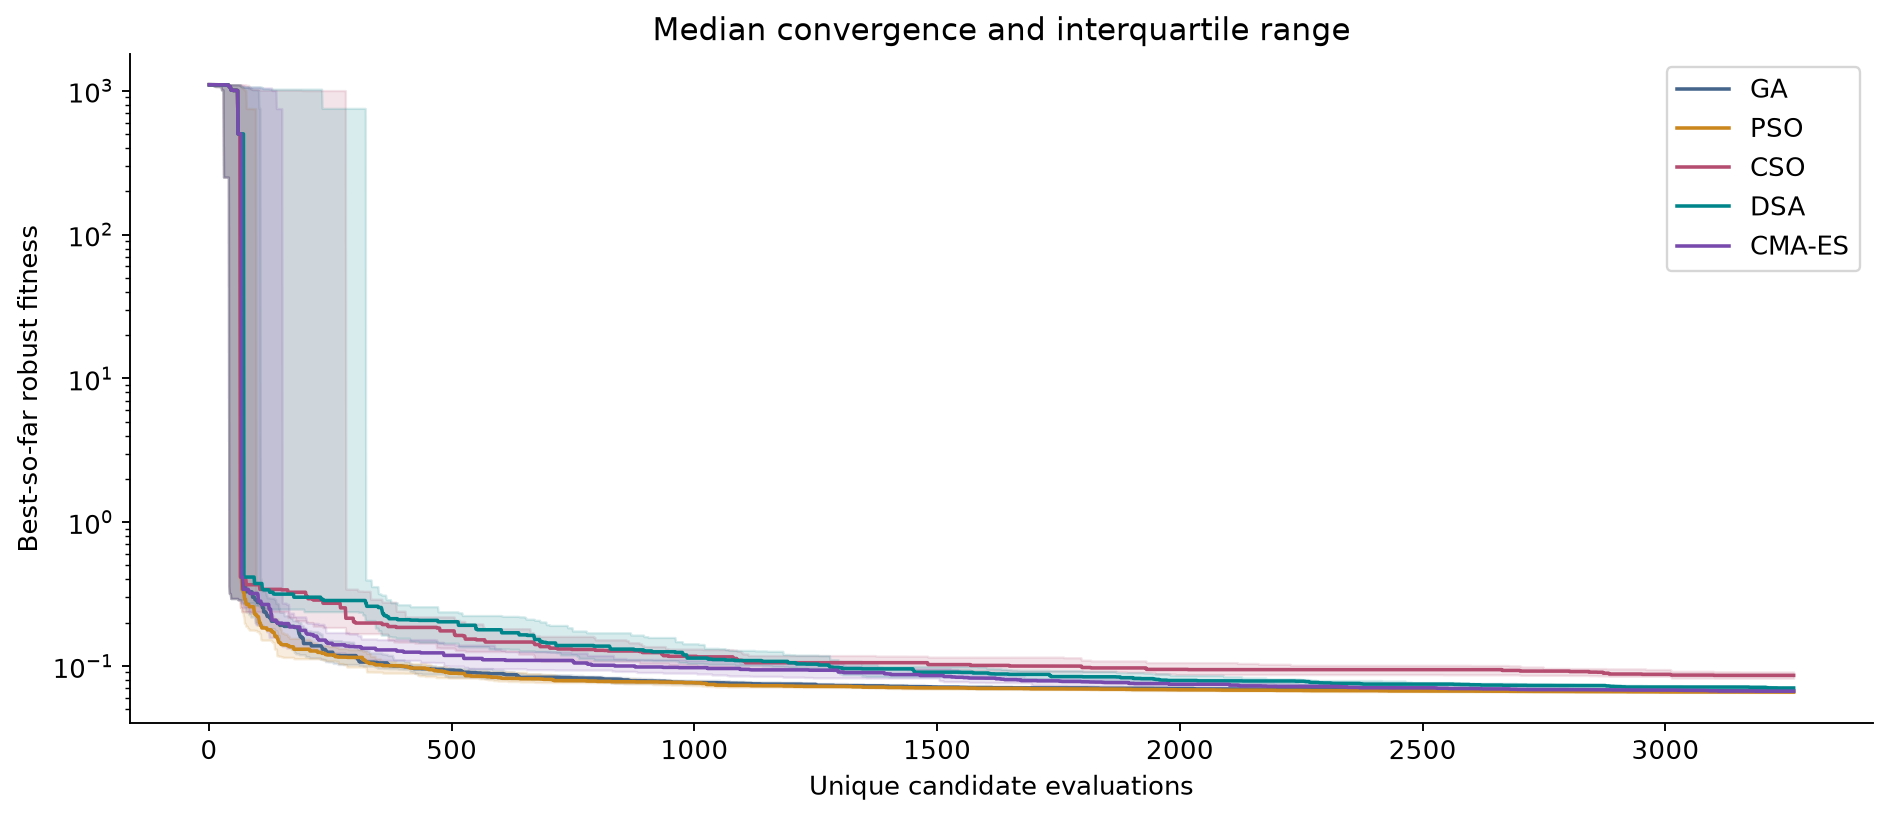

### Files
- [all work/robustness 30 seed study/results/plots/01_training_fitness.png](../all%20work/robustness%2030%20seed%20study/results/plots/01_training_fitness.png)
- [all work/robustness 30 seed study/results/plots/02_convergence.png](../all%20work/robustness%2030%20seed%20study/results/plots/02_convergence.png)
- [all work/robustness 30 seed study/results/plots/03_robustness_speed_tradeoff.png](../all%20work/robustness%2030%20seed%20study/results/plots/03_robustness_speed_tradeoff.png)
- [all work/robustness 30 seed study/results/plots/04_all_cases.png](../all%20work/robustness%2030%20seed%20study/results/plots/04_all_cases.png)
- [all work/robustness 30 seed study/results/plots/05_parameter_sensitivity.png](../all%20work/robustness%2030%20seed%20study/results/plots/05_parameter_sensitivity.png)
- [all work/robustness 30 seed study/results/plots/06_heldout_response_envelopes.png](../all%20work/robustness%2030%20seed%20study/results/plots/06_heldout_response_envelopes.png)

In [5]:
show_source(BENCHMARK/'benchmark.py','Budget')
show_figures(sorted((BENCHMARK/'results/plots').glob('*.png')),limit=2)
file_links(sorted((BENCHMARK/'results/plots').glob('*.png')))
